In [350]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score, root_mean_squared_error
from sklearn.preprocessing import StandardScaler
from category_encoders import OneHotEncoder
from sklearn.pipeline import make_pipeline

# Data Loading, Cleaning and Feature Engineering

### 1. Data Loading

In [9]:
datasets = [
    '/Users/otistran/Documents/WorldQuant/Linear/buenos-aires-real-estate-1.csv',
    '/Users/otistran/Documents/WorldQuant/Linear/buenos-aires-real-estate-2.csv',
    '/Users/otistran/Documents/WorldQuant/Linear/buenos-aires-real-estate-3.csv',
    '/Users/otistran/Documents/WorldQuant/Linear/buenos-aires-real-estate-4.csv',
    '/Users/otistran/Documents/WorldQuant/Linear/buenos-aires-real-estate-5.csv'
]

In [17]:
files = []
for x in datasets:
    data = pd.read_csv(x)
    files.append(data)
len(files)

5

In [19]:
df = pd.concat(files, ignore_index = True)
df.head()

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,apartment,|Argentina|Capital Federal|Villa Crespo|,"-34.6047834183,-58.4586812499",180000.0,USD,2729232.0,180000.0,120.0,110.0,1500.000000,1636.363636,NaN,4.0,NaN,http://villa-crespo.properati.com.ar/12egq_ven...
1,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,NaN,250000.0,USD,3790600.0,250000.0,117.0,120.0,2136.752137,2083.333333,NaN,4.0,NaN,http://ramos-mejia.properati.com.ar/s7pd_venta...
2,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Cast...,"-34.6497002,-58.658073",410000.0,USD,6216584.0,410000.0,410.0,220.0,1000.000000,1863.636364,NaN,NaN,NaN,http://castelar-moron.properati.com.ar/11vgn_v...
3,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Tres de Fe...,"-34.5957086,-58.5669503",180000.0,USD,2729232.0,180000.0,200.0,135.0,900.000000,1333.333333,NaN,5.0,NaN,http://tres-de-febrero.properati.com.ar/7f7u_v...
4,sell,apartment,|Argentina|Capital Federal|Chacarita|,"-34.5846508988,-58.4546932614",129000.0,USD,1955949.6,129000.0,76.0,70.0,1697.368421,1842.857143,NaN,NaN,NaN,http://chacarita.properati.com.ar/10qlv_venta_...


### 2.Data Cleaning

In [93]:
# Filter Capital Federal and Apartments
def filter_df(data):
    return(
    data[lambda x: x["place_with_parent_names"].str.contains("Capital Federal")]
    .query("property_type == 'apartment'")
    .query("price_aprox_usd < 400_000")
)

In [42]:
# Handling Outliers with surface_covered_in_m2
def outliers_df(data):
    return(
        data
        .loc[lambda x: x["surface_covered_in_m2"].between(x["surface_covered_in_m2"].quantile(0.1),
                                                   x["surface_covered_in_m2"].quantile(0.9)
                                                  )]
    )

In [40]:
# Extracting Features from String Columns
def modify_cols(data):
    return (
        data
        .assign(
            lat = lambda x: x["lat-lon"].str.split(",",expand=True)[0].astype(float),
            lon = lambda x: x["lat-lon"].str.split(",",expand=True)[1].astype(float),
            neighborhood = lambda x: x["place_with_parent_names"].str.split("|",expand=True)[3]
    )
    )

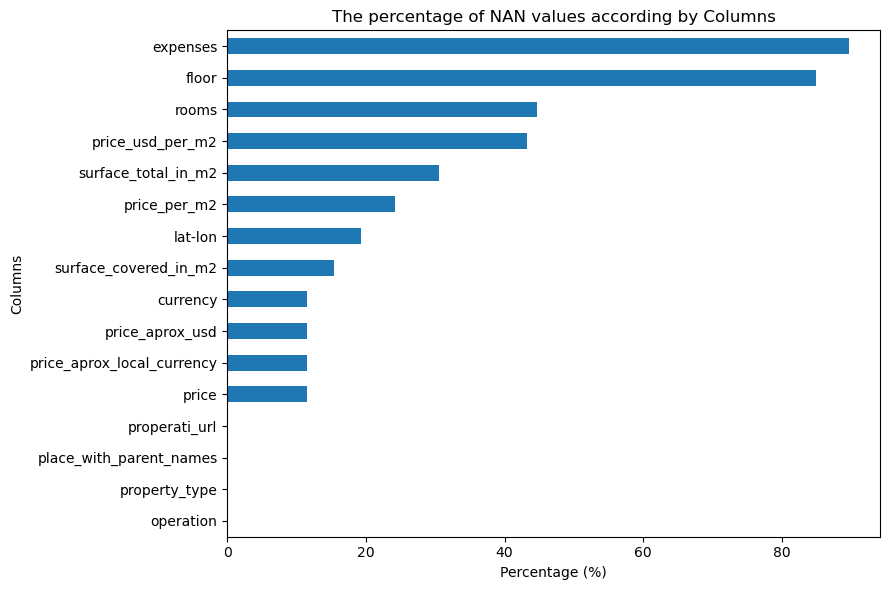

In [56]:
# Missing Values Analysis
nan_columns_pct = (df.isna().sum(axis = 0) * 100/len(df)).sort_values()
fig, ax = plt.subplots(figsize=(9,6))
nan_columns_pct.plot(kind = "barh", ax = ax)
ax.set_xlabel("Percentage (%)")
ax.set_ylabel("Columns")
ax.set_title("The percentage of NAN values according by Columns")
plt.tight_layout()
plt.show()

/opt/anaconda3/lib/python3.12/site-packages/missingno/missingno.py:61: UserWarning: Plotting a sparkline on an existing axis is not currently supported. To remove this warning, set sparkline=False.
  warnings.warn(


<Axes: >

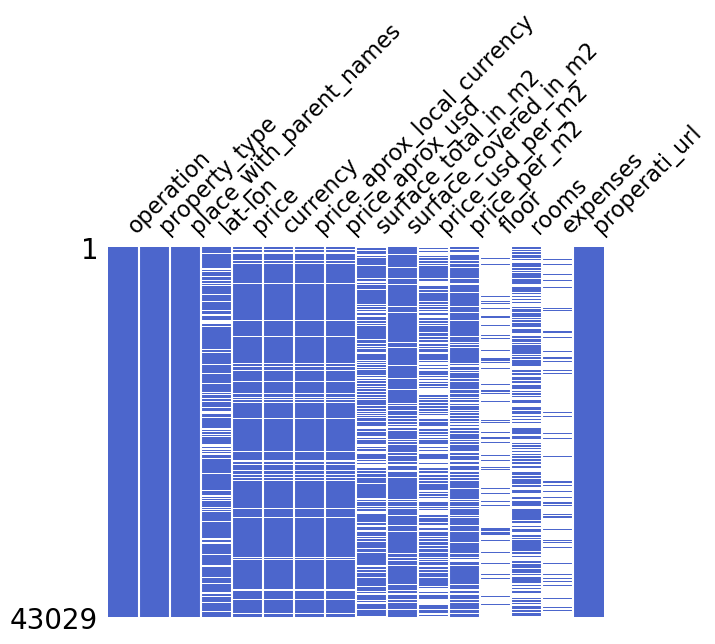

In [64]:
! pip install missingno -q
import missingno as msno
fig, ax = plt.subplots()
msno.matrix(df, color = (0.3,0.4,0.8), ax=ax)

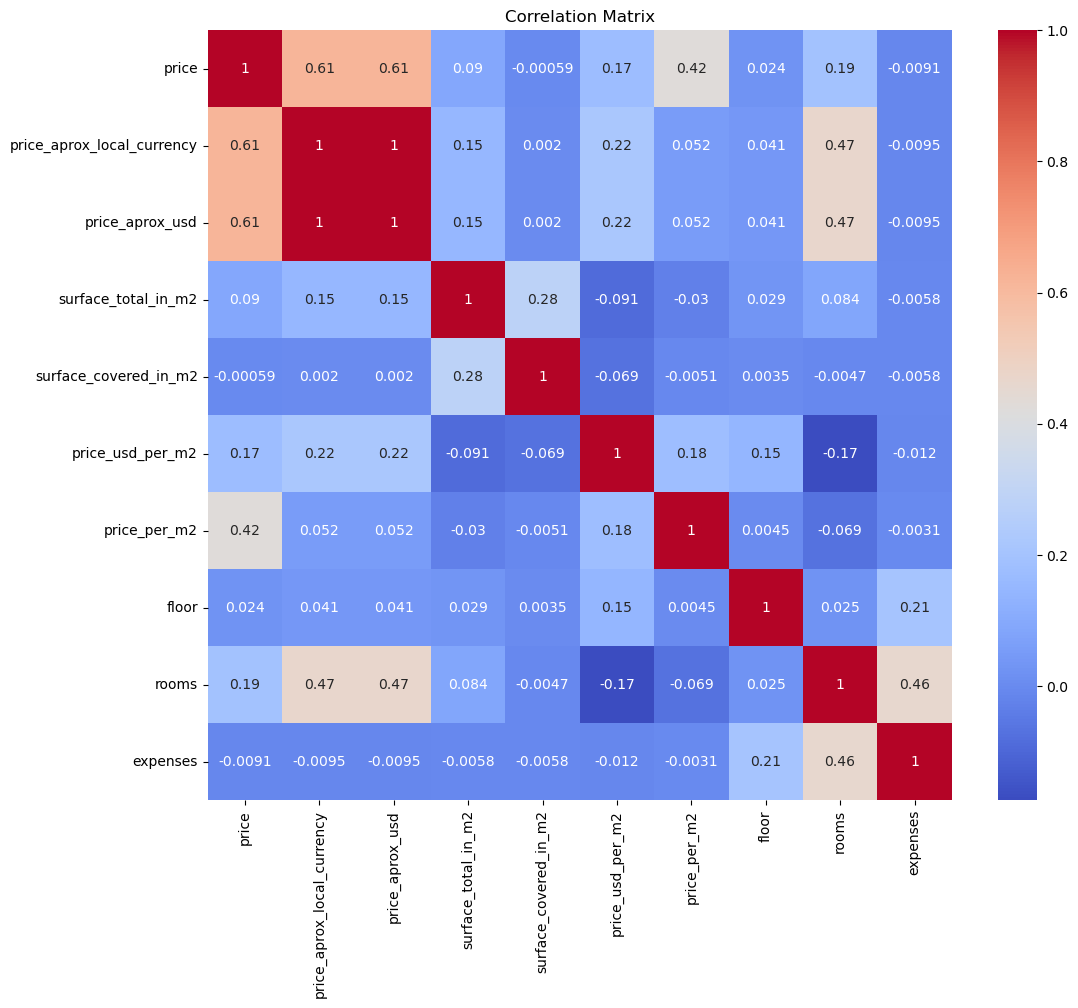

In [69]:
# Multicollinearity Analysis
corr_matrix = df.select_dtypes(include = "number").corr()
fig, ax = plt.subplots(figsize = (12,10))
sns.heatmap(corr_matrix, annot = True, cmap = "coolwarm", ax=ax)
ax.set_title("Correlation Matrix")
plt.show()

In [75]:
### Drop Unneccessary Columns
drop_cols = [
    "expenses","floor","rooms" #High missingness
    "price","price_aprox_local_currency","price_usd_per_m2","price_per_m2" # Data leakage
    "surfaced_total_in_m2" # Multicollinearity
    "properati_url",
    "lat-lon",
    "place_with_parent_names",
]

In [109]:
def clean_files(df):
    drop_cols = [
    "expenses","floor","rooms", #High missingness
    "price","price_aprox_local_currency","price_usd_per_m2","price_per_m2", # Data leakage
    "surface_total_in_m2", # Multicollinearity
    "properati_url",
    "lat-lon",
    "place_with_parent_names",
    "operation",
    "property_type",
    "currency"
]
    return(
        df
        .pipe(filter_df)
        .pipe(outliers_df)
        .pipe(modify_cols)
        .drop(columns = drop_cols)
        .dropna()
    )

In [111]:
clean_df = clean_files(df)

In [119]:
clean_df.head()

,price_aprox_usd,surface_covered_in_m2,lat,lon,neighborhood
4,129000.0,70.0,-34.584651,-58.454693,Chacarita
9,87000.0,42.0,-34.638979,-58.500115,Villa Luro
29,118000.0,54.0,-34.615847,-58.459957,Caballito
40,57000.0,42.0,-34.625222,-58.382382,Constitución
41,90000.0,50.0,-34.610610,-58.412511,Once


# First Model: Predict single relationship - Surface Covered

### 1. Logistics Regression

In [150]:
X = clean_df[["surface_covered_in_m2"]]
y = clean_df["price_aprox_usd"]
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state=42)

In [152]:
# Establishing Baseline
y_mean = y_train.mean() 
y_pred_baseline = [y_mean]*len(y_test)
mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
print(mae_baseline)

44515.61274011767


In [160]:
# Linear regression
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)
# Evaluate Model
y_pred_train = model_lr.predict(X_train)
mae_train = mean_absolute_error(y_train,y_pred_train)
rmse_train = root_mean_squared_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

In [164]:
# Test Set Performance
y_pred_test = model_lr.predict(X_test)
mae_test = mean_absolute_error(y_test,y_pred_test)
rmse_test = root_mean_squared_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

In [170]:
# Metrics Comparision
metrics_comparison = pd.DataFrame({
    "Metric": ["MAE","RMSE", "R2"],
    "Training": [mae_train,rmse_train,r2_train],
    "Test": [mae_test, rmse_test,r2_test]
})

print(metrics_comparison)

  Metric      Training          Test
0    MAE  31161.180943  30176.983140
1   RMSE  43087.894408  41814.016022
2     R2      0.479095      0.471974


In [174]:
# Coefficients
intercept = model_lr.intercept_
coefficient = model_lr.coef_[0]

print(intercept)
print(coefficient)

10695.281454811178
2282.213461952031


### 2. Predicted vs. Actual Plot

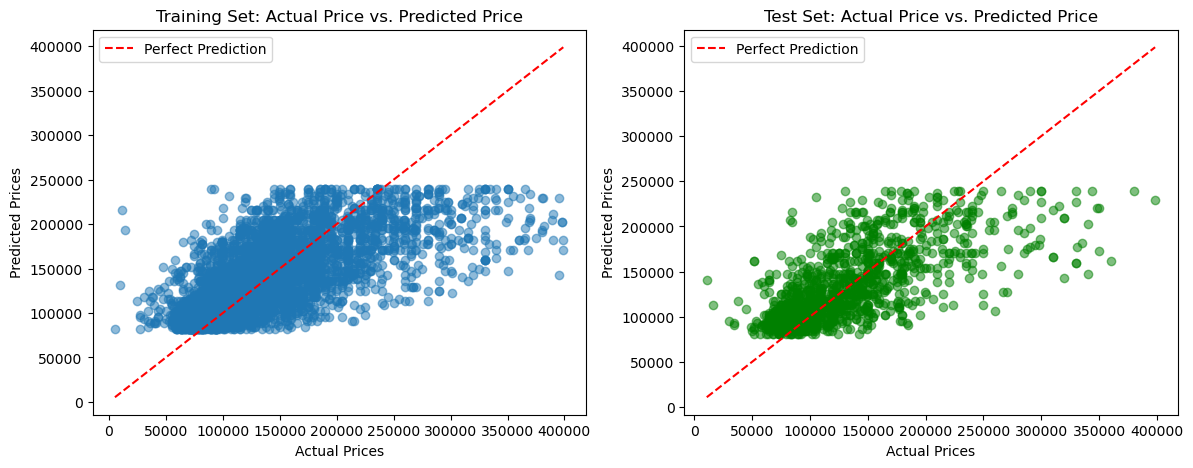

In [195]:
fig, axes = plt.subplots(1,2, figsize = (14,5))

# Training set
axes[0].scatter(y_train, y_pred_train, alpha = 0.5)
axes[0].plot([y_train.min(),y_train.max()],
             [y_train.min(),y_train.max()],linestyle="--", color="red", label="Perfect Prediction")
axes[0].set_xlabel("Actual Prices")
axes[0].set_ylabel("Predicted Prices")
axes[0].set_title("Training Set: Actual Price vs. Predicted Price")
axes[0].legend()

# Testing set
axes[1].scatter(y_test, y_pred_test, alpha = 0.5, color = "green")
axes[1].plot([y_test.min(),y_test.max()],
             [y_test.min(),y_test.max()],linestyle="--", color="red", label="Perfect Prediction")
axes[1].set_xlabel("Actual Prices")
axes[1].set_ylabel("Predicted Prices")
axes[1].set_title("Test Set: Actual Price vs. Predicted Price")
axes[1].legend()

### 3. Residual Analysis

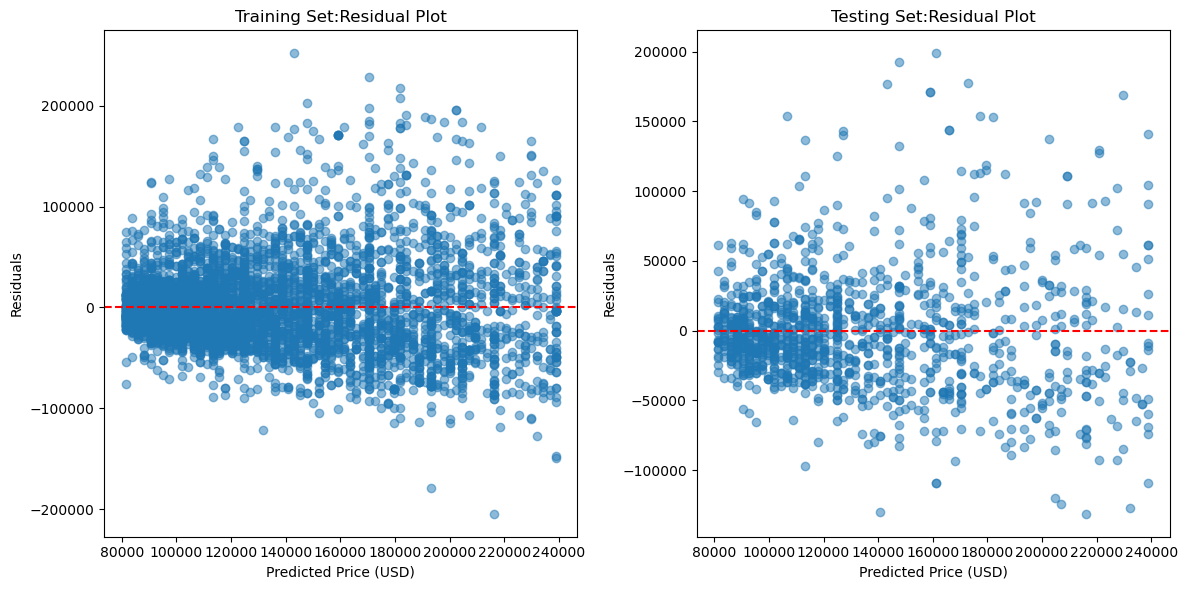

In [206]:
residuals_train = y_train - y_pred_train
residuals_test = y_test - y_pred_test
fig, axes = plt.subplots(1,2, figsize=(12,6))

### Training Residuals 
axes[0].scatter(y_pred_train,residuals_train, alpha=0.5)
axes[0].axhline(y=0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted Price (USD)")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Training Set:Residual Plot")

### Test residuals 

axes[1].scatter(y_pred_test,residuals_test, alpha=0.5)
axes[1].axhline(y=0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted Price (USD)")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Testing Set:Residual Plot")

plt.tight_layout()
plt.show()

# Regularization Regression

In [215]:
clean_df = clean_df.reset_index(drop = True)

In [221]:
features = ["surface_covered_in_m2","lat","lon","neighborhood"]
target = "price_aprox_usd"
X = clean_df[features]
y = clean_df[target]

In [223]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(X,y,test_size = 0.2,random_state=42)

### 1. Ridge Regression

In [226]:
model_ridge = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    Ridge(alpha=1)
)
model_ridge.fit(X_train2, y_train2)

/opt/anaconda3/lib/python3.12/site-packages/sklearn/externals/_numpydoc/docscrape.py:420: UserWarning: Unknown section Example
  self[section] = content


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('onehotencoder', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['su...m2', 'lat', 'lon', 'ne...od']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,cols,['neighborhood']
,use_cat_names,True
,verbose,0
,drop_invariant,False


In [234]:
# Training set
y_pred_ridge_train = model_ridge.predict(X_train2)
rmse_ridge_train = root_mean_squared_error(y_train2, y_pred_ridge_train)

# Testing set
y_pred_ridge_test = model_ridge.predict(X_test2)
rmse_ridge_test = root_mean_squared_error(y_test2, y_pred_ridge_test)

print(rmse_ridge_train)
print(rmse_ridge_test)

34200.4350860392
33087.8456938373


### 2. Lasso Regression

In [241]:
model_lasso = make_pipeline(
    OneHotEncoder(use_cat_names = True),
    StandardScaler(),
    Lasso(alpha = 100,max_iter = 10000)
)
model_lasso.fit(X_train2, y_train2)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('onehotencoder', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['su...m2', 'lat', 'lon', 'ne...od']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,cols,['neighborhood']
,use_cat_names,True
,verbose,0
,drop_invariant,False


In [295]:
# y_pred_lasso_test = model_lasso.predict(X_test2)
rmse_lasso_train = root_mean_squared_error(y_train2, model_lasso.predict(X_train2))
rmse_lasso_test = root_mean_squared_error(y_test2, model_lasso.predict(X_test2))

print(rmse_lasso_train)
print(rmse_lasso_test)

34224.8250104311
33053.24227955067


### 3. Hyperparameter Tunning

In [303]:
# Ridge 
alphas = [0.001, 0.01,0.1, 1,10,100,1000,10000,100000,1000000]
ridge_results = []

for a in alphas:
    model = make_pipeline(
        OneHotEncoder(use_cat_names = True),
        StandardScaler(),
        Ridge(alpha=a)
    )
    model.fit(X_train2, y_train2)
    rmse_train = root_mean_squared_error(y_train2, model.predict(X_train2))
    rmse_test = root_mean_squared_error(y_test2, model.predict(X_test2))
    ridge_results.append({
        "alpha": a,
        "rmse_train": rmse_train,
        "rmse_test": rmse_test
    })
df_ridge_results = pd.DataFrame(ridge_results)

In [305]:
df_ridge_results

,alpha,rmse_train,rmse_test
0,0.001,34200.432952,33088.372087
1,0.010,34200.432953,33088.367313
2,0.100,34200.432974,33088.319603
3,1.000,34200.435086,33087.845694
4,10.000,34200.639955,33083.415038
5,100.000,34216.977947,33062.388861
6,1000.000,35069.439956,33744.376028
7,10000.000,46235.626251,44495.846605
8,100000.000,57461.877687,55406.360980
9,1000000.000,59460.655403,57344.013143


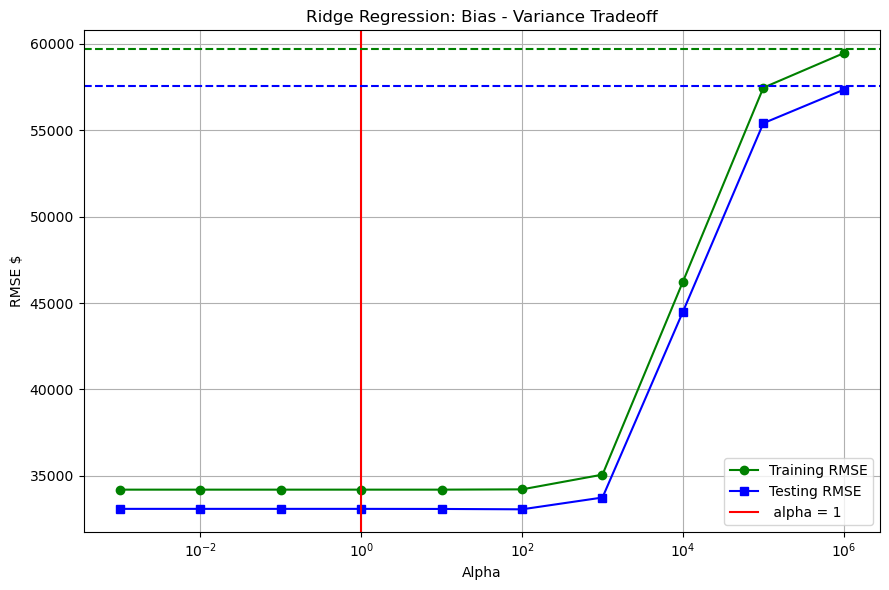

In [307]:
fig, ax = plt.subplots(figsize = (9,6))
ax.plot(df_ridge_results["alpha"], 
        df_ridge_results["rmse_train"],
        marker = "o", color = "green",
       label="Training RMSE")
ax.plot(df_ridge_results["alpha"],
        df_ridge_results["rmse_test"],
        marker = "s", color = "blue",
       label="Testing RMSE")
ax.axvline(x=1, color = "red", label = " alpha = 1")
ax.axhline(y_train2.std(), linestyle = "--",color = "green")
ax.axhline(y_test2.std(), linestyle = "--", color = "blue")
ax.set_xscale("log")
ax.set_xlabel("Alpha")
ax.set_ylabel("RMSE $")
ax.set_title("Ridge Regression: Bias - Variance Tradeoff")
ax.grid()
plt.legend()
plt.tight_layout()
plt.show()

In [319]:
# Lasso
lasso_results = []
alphas_lasso = [0.001, 0.01,0.1, 1,10,100,1000,10000,100000,1000000]
for a in alphas_lasso:
    model = make_pipeline(
        OneHotEncoder(use_cat_names=True),
        StandardScaler(),
        Lasso(alpha =a, max_iter = 10000
    ))
    model.fit(X_train2, y_train2)
    rmse_train_lasso = root_mean_squared_error(y_train2, model.predict(X_train2))
    rmse_test_lasso = root_mean_squared_error(y_test2, model.predict(X_test2))
    non_zero_features = (model.named_steps["lasso"].coef_ !=0).sum()
    lasso_results.append({
        "alpha": a,
        "rmse_train_lasso": rmse_train_lasso,
        "rmse_test_lasso": rmse_test_lasso,
        "non_zero_features": non_zero_features
    })
df_lasso_results = pd.DataFrame(lasso_results)

/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.497177e+11, tolerance: 1.781e+09
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.497203e+11, tolerance: 1.781e+09
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.669860e+

In [320]:
df_lasso_results

,alpha,rmse_train_lasso,rmse_test_lasso,non_zero_features
0,0.001,34200.432952,33088.371804,59
1,0.010,34200.432953,33088.364476,59
2,0.100,34200.432980,33088.297202,59
3,1.000,34200.435537,33087.686878,58
4,10.000,34200.691205,33081.797922,58
5,100.000,34224.825010,33053.242280,56
6,1000.000,34772.392675,33646.034886,27
7,10000.000,41807.119346,40432.830656,3
8,100000.000,59700.248509,57576.128347,0
9,1000000.000,59700.248509,57576.128347,0


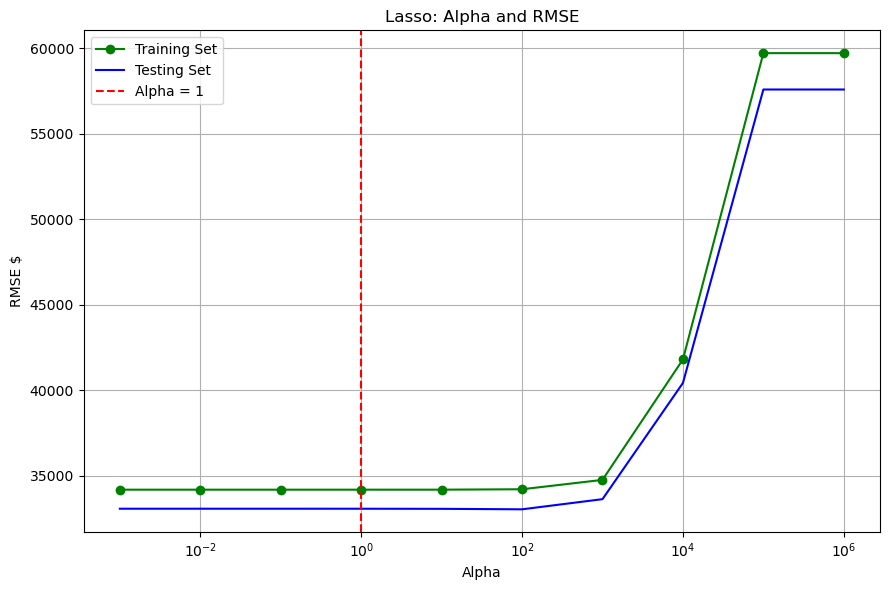

In [343]:
fig, ax = plt.subplots(figsize = (9,6))
ax.plot(df_lasso_results["alpha"],df_lasso_results["rmse_train_lasso"],
        marker = "o", color = "green", label = "Training Set")
ax.plot(df_lasso_results["alpha"], df_lasso_results["rmse_test_lasso"],
        color = "blue", label = "Testing Set")
ax.axvline(x=1, color = "red", linestyle="--", label = "Alpha = 1")
ax.set_xlabel("Alpha")
ax.set_xscale("log")
ax.set_ylabel("RMSE $")
ax.set_title("Lasso: Alpha and RMSE")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

### 4. RidgeCV and LassoCV

In [356]:
# Automatically finds the best alpha
ridge_cv_model = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    RidgeCV(alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000, 1000000], cv = 5)
)
ridge_cv_model.fit(X_train2, y_train2)
# Extract the optimal alpha
optimal_alpha = ridge_cv_model.named_steps["ridgecv"].alpha_
print(f"RidgeCV selected alpha : {optimal_alpha}")
print(f"RidgeCV test RMSE: {root_mean_squared_error(y_test2, ridge_cv_model.predict(X_test2))}")

# LassoCV
lasso_cv_model = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    LassoCV(alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000, 1000000],
            cv = 5, max_iter=10000)
)
lasso_cv_model.fit(X_train2, y_train2)

optimal_lassocv_alpha = lasso_cv_model.named_steps["lassocv"].alpha_
print(f"LassoCV selected alpha : {optimal_lassocv_alpha}")
print(f"LassoCV test RMSE: {root_mean_squared_error(y_test2, lasso_cv_model.predict(X_test2))}")

RidgeCV selected alpha : 100.0
RidgeCV test RMSE: 33062.388861120155
LassoCV selected alpha : 10.0
LassoCV test RMSE: 33081.79792190928


### 5. Visualizing and Interpreting Coefficients

In [361]:
# Extract coefficients from the Lasso step
coefficients = model_lasso.named_steps["lasso"].coef_

# Extract feature names from the OneHotEncoder step

features = model_lasso.named_steps["onehotencoder"].get_feature_names_out()

# Create Series

features_lasso = pd.Series(coefficients, index = features)

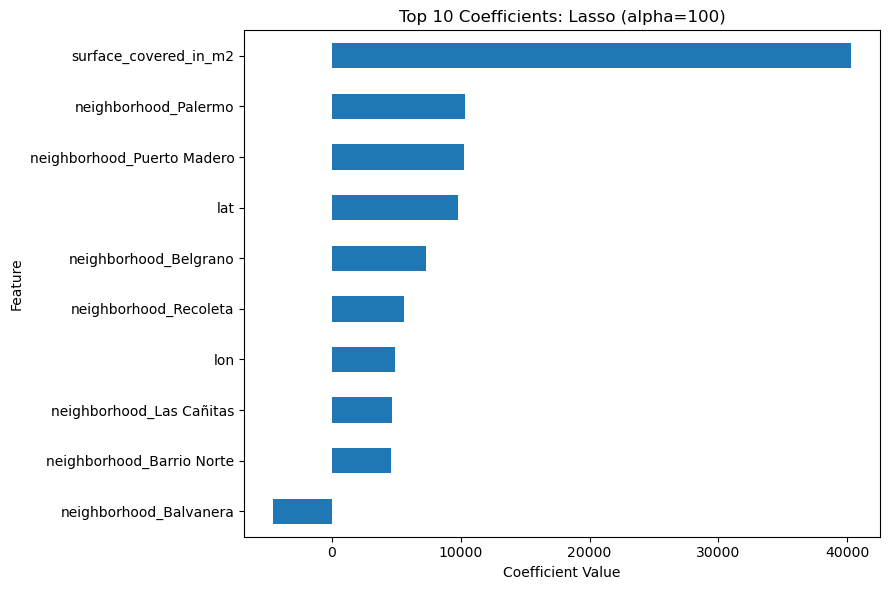

In [365]:
fig, ax = plt.subplots(figsize=(9, 6))
features_lasso.sort_values(key=abs).tail(10).plot(kind="barh", ax=ax)
ax.set_title("Top 10 Coefficients: Lasso (alpha=100)")
ax.set_xlabel("Coefficient Value")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

In [371]:
# Show top 5 positive and negative coefficients
print("=" * 60)
print("TOP 5 POSITIVE FEATURES (Increase Price)")
print("=" * 60)
top_positive = features_lasso.nlargest(5)
for feature, coef in top_positive.items():
    print(f"{feature:40} : ${coef:>10,.2f}")

print("\n" + "=" * 60)
print("TOP 5 NEGATIVE FEATURES (Decrease Price)")
print("=" * 60)
top_negative = features_lasso.nsmallest(5)
for feature, coef in top_negative.items():
    print(f"{feature:40} : ${coef:>10,.2f}")

print("\n" + "=" * 60)
print("INTERPRETATION GUIDE")
print("=" * 60)
print("Remember: These coefficients are on STANDARDIZED features.")
print("A feature's importance depends on both its coefficient AND")
print("which other features Lasso eliminated. This is the 'feature selection'")
print("effect of Lasso in action.")

TOP 5 POSITIVE FEATURES (Increase Price)
surface_covered_in_m2                    : $ 40,288.95
neighborhood_Palermo                     : $ 10,307.79
neighborhood_Puerto Madero               : $ 10,259.33
lat                                      : $  9,774.24
neighborhood_Belgrano                    : $  7,279.83

TOP 5 NEGATIVE FEATURES (Decrease Price)
neighborhood_Balvanera                   : $ -4,560.41
neighborhood_Once                        : $ -3,978.74
neighborhood_Boca                        : $ -3,853.26
neighborhood_Congreso                    : $ -2,671.56
neighborhood_Constitución                : $ -2,195.16

INTERPRETATION GUIDE
Remember: These coefficients are on STANDARDIZED features.
A feature's importance depends on both its coefficient AND
which other features Lasso eliminated. This is the 'feature selection'
effect of Lasso in action.


### 6. Residual Analyis for Lasso

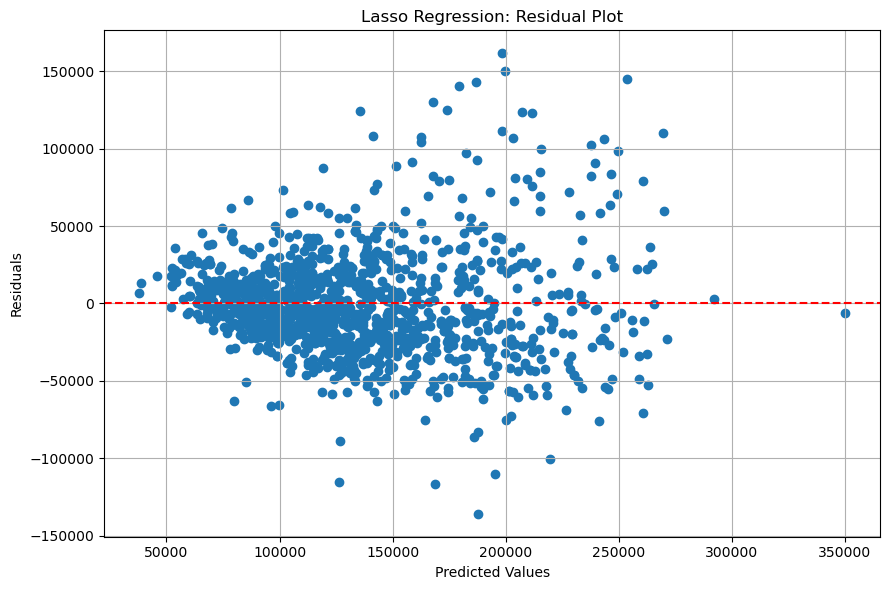

In [390]:
# Get residuals
y_pred_lasso = model_lasso.predict(X_test2)
residuals_lasso = y_test2 - y_pred_lasso

# Create residual plot
fig, ax = plt.subplots(figsize = (9,6))
ax.scatter(y_pred_lasso, residuals_lasso)
ax.axhline(y=0, linestyle="--", color = "red", label = "Perfect Prediction")
ax.set_xlabel("Predicted Values")
ax.set_ylabel("Residuals")
ax.set_title("Lasso Regression: Residual Plot")
plt.grid()
plt.tight_layout()
plt.show()

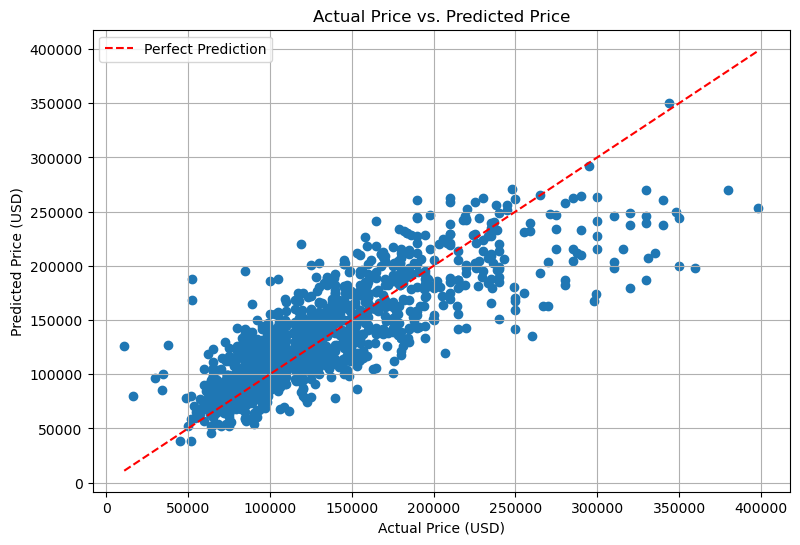

In [406]:
fig, ax = plt.subplots(figsize = (9,6))
ax.scatter(y_test2, y_pred_lasso)
ideal_line = np.linspace(y_test2.min(), y_test2.max(), 100)
ax.plot(ideal_line, ideal_line, linestyle="--", color = "red", label = "Perfect Prediction")
ax.set_xlabel("Actual Price (USD)")
ax.set_ylabel("Predicted Price (USD)")
ax.set_title("Actual Price vs. Predicted Price")
plt.legend()
plt.grid()
plt.show()